# 05 - Impulse response and rolling regime robustness: Gold and silver

This notebook builds on `03_Bivariate_VAR_VECM.ipynb` and `04_Multivariate_VAR_VECM.ipynb`: it re-estimates the retained VAR and local VECM specifications from both notebooks, then covers what was deliberately left out there: Granger and instantaneous causality, the Cholesky decomposition, impulse response functions (IRF) and the forecast error variance decomposition (FEVD), for both the bivariate and multivariate systems.

The last section checks whether the VAR's impulse responses are stable across the six macro regimes used in `02_Stationarity_and_Cointegration.ipynb`, or specific to the full-sample estimation.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.api import VAR

from preprocessing import clean_for_model
from var_vecm import (
    fit_vecm,
    granger_causality_table,
    instantaneous_causality_table,
    cholesky_decomposition,
    orthogonal_shocks,
    compute_irf,
    compute_fevd,
    fevd_table,
    granger_causality_lag_sweep,
    compute_girf,
    var_irf_by_subperiod,
    irf_subperiod_comparison,
)
from plots import plot_irf

Both VARs are re-estimated on the full sample with the lag orders retained in notebooks 03 and 04 (VAR(1) for the bivariate system, VAR(2) for the multivariate one). The two local VECMs are re-estimated on the cointegration windows identified there, with the same specification (`k_ar_diff = 0` on 2015-05-05 to 2016-02-12 for the bivariate case, `k_ar_diff = 1` on 2013-01-22 to 2017-09-05 for the multivariate case, rank 1 and a constant in both).

In [2]:
df = pd.read_csv("../data/processed/gold_silver_processed.csv", index_col=0, parse_dates=True)

diff_cols_bi = ["dlog_gold", "dlog_silver"]
df_bi_clean = clean_for_model(df[diff_cols_bi])

final_var_bi = VAR(df_bi_clean).fit(1)
print(final_var_bi.summary())

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Thu, 08, Oct, 2026
Time:                     06:33:39
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                   -17.8157
Nobs:                     6107.00    HQIC:                  -17.8201
Log likelihood:           37095.6    FPE:                1.81909e-08
AIC:                     -17.8223    Det(Omega_mle):     1.81731e-08
--------------------------------------------------------------------
Results for equation dlog_gold
                    coefficient       std. error           t-stat            prob
---------------------------------------------------------------------------------
const                  0.000371         0.000140            2.655           0.008
L1.dlog_gold          -0.003759         0.020440           -0.184           0.854
L1.dlog_silver        -0.007176         0.011271    

In [3]:
df_macro = pd.read_csv("../data/processed/gold_silver_macro_processed.csv", index_col=0, parse_dates=True)

diff_cols_multi = ["dlog_gold", "dlog_silver", "dlog_dxy", "dus10y"]
df_multi_clean = clean_for_model(df_macro[diff_cols_multi])

final_var_multi = VAR(df_multi_clean).fit(2)
print(final_var_multi.summary())

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Thu, 08, Oct, 2026
Time:                     06:33:39
--------------------------------------------------------------------
No. of Equations:         4.00000    BIC:                   -34.4053
Nobs:                     6147.00    HQIC:                  -34.4310
Log likelihood:           71012.8    FPE:                1.09867e-15
AIC:                     -34.4447    Det(Omega_mle):     1.09226e-15
--------------------------------------------------------------------
Results for equation dlog_gold
                    coefficient       std. error           t-stat            prob
---------------------------------------------------------------------------------
const                  0.000381         0.000138            2.751           0.006
L1.dlog_gold          -0.037523         0.021096           -1.779           0.075
L1.dlog_silver        -0.007797         0.011410    

In [4]:
log_cols_bi = ["log_gold", "log_silver"]
vecm_data_bi = df.loc["2015-05-05":"2016-02-12", log_cols_bi].dropna()

vecm_res_bi = fit_vecm(vecm_data_bi, k_ar_diff=0, coint_rank=1, deterministic="co")

In [5]:
log_cols_multi = ["log_gold", "log_silver", "log_dxy", "us10y"]
vecm_data_multi = df_macro.loc["2013-01-22":"2017-09-05", log_cols_multi].dropna()

vecm_res_multi = fit_vecm(vecm_data_multi, k_ar_diff=1, coint_rank=1, deterministic="co")

## 1. Causality tests (bivariate VAR)

### 1.1 Granger causality

In [6]:
granger_bi = granger_causality_table(final_var_bi, ["dlog_gold", "dlog_silver"])
granger_bi

,Causing,Caused,F stat,p-value,Decision
0,dlog_silver,dlog_gold,0.405392,0.524329,Fail to reject H0
1,dlog_gold,dlog_silver,0.815848,0.366415,Fail to reject H0


Neither direction is significant: silver → gold gives F ≈ 0.41 (p ≈ 0.52) and gold → silver F ≈ 0.82 (p ≈ 0.37).

With a single lag, the Granger test is the same restriction as the t-test on the cross coefficient of the VAR(1) in notebook 03 (F = t²: 0.637² ≈ 0.41 and 0.903² ≈ 0.82), so this is a confirmation of that reading and not new evidence: yesterday's return on one metal does not help forecast today's return on the other.

### 1.2 Instantaneous causality

In [7]:
inst_bi = instantaneous_causality_table(final_var_bi, causing=["dlog_gold"])
inst_bi

,Variables tested,Null hypothesis,Statistic,p-value,Decision
0,dlog_gold ↔ dlog_silver,No instantaneous causality,2309.411666,0.0,Reject H0 (contemporaneous dependence)


The test rejects very strongly (Wald statistic ≈ 2309 with 1 degree of freedom, p-value numerically zero). This is the formal counterpart of the 0.78 residual correlation reported in notebook 03.

The test is symmetric: it says the two innovations move together within the day, not which metal moves the other. Taken with §1.1, the link between gold and silver at daily frequency is contemporaneous and not sequential.

## 2. Causality tests (multivariate VAR)

For the multivariate system the question is narrower than "all pairs": do the dollar and the 10-year yield Granger-cause gold? Since the answer can depend on the number of lags allowed, the test is repeated for every lag order from 1 to 100 instead of relying on the retained VAR(2) alone. The sweep reports the first lag at which the null of no causality stops being rejected at 5%.

### 2.1 Granger causality: robustness across lags (dollar, rates → gold)

In [8]:
granger_dxy_gold, stop_lag_dxy = granger_causality_lag_sweep(
    df_multi_clean, causing="dlog_dxy", caused="dlog_gold", max_lag=100
)
print("First lag with a non-rejection:", stop_lag_dxy)
granger_dxy_gold.tail()

First lag with a non-rejection: None


,Lag,F_stat,p_value,Decision (5%)
95,96,1.5308,0.0007,Reject H0
96,97,1.5181,0.0009,Reject H0
97,98,1.5446,0.0005,Reject H0
98,99,1.5287,0.0006,Reject H0
99,100,1.5169,0.0008,Reject H0


`stop_lag_dxy` is `None`: the null of no causality from the dollar to gold is rejected at every lag order from 1 to 100, and the p-values are between 0.0005 and 0.0009 at lags 96 to 100.

This is a stronger statement than the significant L1.dlog_dxy coefficient of notebook 04: the predictive content of the dollar for gold does not depend on how many lags are allowed. The sweep is run on the full sample (the original study used the training sample only).

In [9]:
granger_us10y_gold, stop_lag_rate = granger_causality_lag_sweep(
    df_multi_clean, causing="dus10y", caused="dlog_gold", max_lag=100
)
print("First lag with a non-rejection:", stop_lag_rate)
granger_us10y_gold.tail()

First lag with a non-rejection: 84


,Lag,F_stat,p_value,Decision (5%)
95,96,1.2486,0.0517,Fail to reject H0
96,97,1.2982,0.0270,Reject H0
97,98,1.3286,0.0173,Reject H0
98,99,1.3769,0.0083,Reject H0
99,100,1.3667,0.0094,Reject H0


For rates the result is weaker. The null is rejected at every lag from 1 to 83, and lag 84 is the first non-rejection. It is not a clean cut-off: at the end of the sweep lag 96 is not rejected (p = 0.052) while lags 97 to 100 are rejected again (p between 0.008 and 0.027).

The rate → gold link is therefore well established at short and medium lag orders and borderline at very long ones, whereas the dollar → gold link never weakens. This fits the VAR(2) coefficients of notebook 04, where the lagged dollar effect on gold is also the larger of the two.

### 2.2 Instantaneous causality

In [10]:
# test_inst_causality raises an IndexError from statsmodels when `causing`
# contains more than one variable in a system with k>2 (known library
# limitation, not specific to this dataset). Testing one variable at a
# time against the rest of the system instead.
for var in ["dlog_gold", "dlog_silver", "dlog_dxy", "dus10y"]:
    try:
        res = instantaneous_causality_table(final_var_multi, causing=[var])
        print(res.to_string(index=False))
    except Exception as e:
        print(f"{var}: error - {e}")
    print()

                           Variables tested            Null hypothesis   Statistic  p-value                               Decision
dlog_gold ↔ dlog_silver ↔ dlog_dxy ↔ dus10y No instantaneous causality 2386.812562      0.0 Reject H0 (contemporaneous dependence)

                           Variables tested            Null hypothesis  Statistic  p-value                               Decision
dlog_gold ↔ dlog_silver ↔ dlog_dxy ↔ dus10y No instantaneous causality 2354.59197      0.0 Reject H0 (contemporaneous dependence)

                           Variables tested            Null hypothesis  Statistic       p-value                               Decision
dlog_gold ↔ dlog_silver ↔ dlog_dxy ↔ dus10y No instantaneous causality 973.940703 8.093101e-211 Reject H0 (contemporaneous dependence)

                           Variables tested            Null hypothesis  Statistic      p-value                               Decision
dlog_gold ↔ dlog_silver ↔ dlog_dxy ↔ dus10y No instantaneous causality 

All four tests reject, with 3 degrees of freedom each: 2386.8 for gold, 2354.6 for silver, 973.9 for the dollar and 366.3 for the 10-year yield (p-values numerically zero).

No variable is contemporaneously independent of the rest of the system, but the strength differs. Gold and silver are the most tied to the others, mainly through each other (residual correlation 0.78). The dollar is clearly linked to both metals within the day (−0.40 with gold, −0.38 with silver). The yield is the least connected (−0.17 with gold, −0.06 with silver, 0.18 with the dollar).

## 3. Orthogonalization and impulse response functions (bivariate VAR)

The residuals of the two equations are strongly correlated, so a "gold shock" and a "silver shock" cannot be read off the VAR directly. The Cholesky decomposition Σ = PP' turns them into uncorrelated shocks, at the price of an ordering assumption: with gold first, a gold shock can move silver within the day, but a silver shock cannot move gold within the day.

This ordering follows the reading of gold as the price leader in the local VECM (notebook 03 §2.7: silver's adjustment coefficient is significant, gold's is not). It remains an assumption, and §4 shows how much of the result depends on it.

In [11]:
P_bi = cholesky_decomposition(final_var_bi)
shocks_bi = orthogonal_shocks(final_var_bi, P_bi)

print("P (Cholesky):")
print(P_bi)
print("\nVar(shocks), should be close to the identity matrix:")
print(shocks_bi.cov())

P (Cholesky):
[[0.01089716 0.        ]
 [0.01541076 0.01237088]]

Var(shocks), should be close to the identity matrix:
              v1            v2
v1  9.996725e-01 -3.589951e-16
v2 -3.589951e-16  9.996725e-01


P is lower triangular, as imposed by the ordering. A one-standard-deviation gold shock moves gold by about 1.09% on the day and silver by about 1.54%; silver's own orthogonal shock is worth about 1.23%.

The covariance matrix of the transformed shocks has 0.9997 on the diagonal and zeros off the diagonal (order 1e-16). The small gap to 1 is only a degrees-of-freedom convention (Σ is estimated with T − 3 in the denominator, the sample covariance with T − 1), so the orthogonalization is exact.

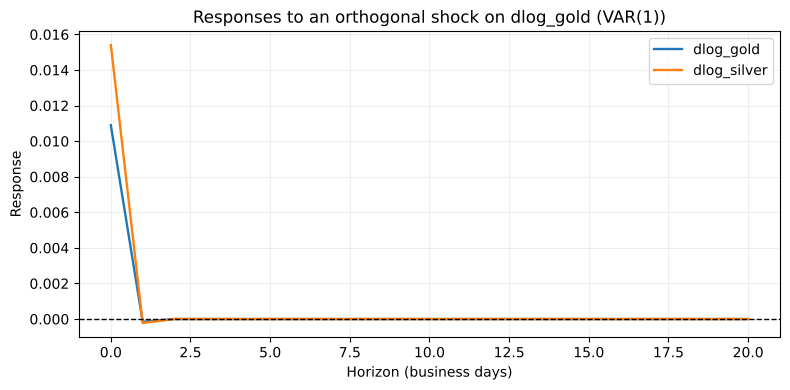

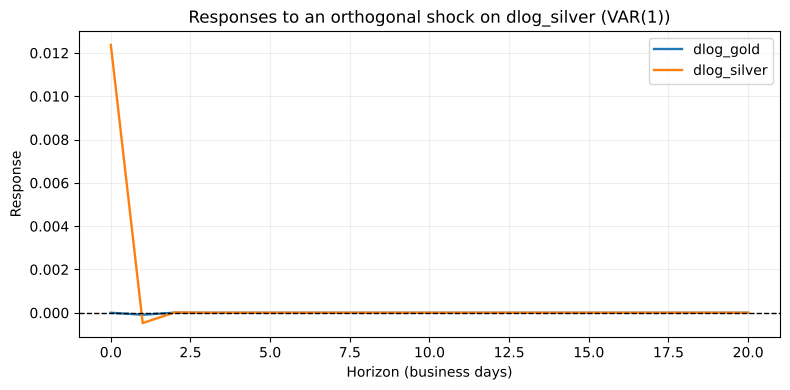

In [12]:
H = 20       # VAR on returns: responses die out within a few days
H_VECM = 100  # VECM on log-levels: responses settle on a permanent level, more slowly

IRF_bi = compute_irf(final_var_bi, P_bi, H)

plot_irf(IRF_bi, ["dlog_gold", "dlog_silver"], H, model_label="VAR(1)")

Everything happens on impact. After a gold shock, gold moves by 1.09% and silver by 1.54% at h = 0; at h = 1 both responses are already around −0.02%, under 2% of the impact, and they are indistinguishable from zero from h = 2 onwards. After a silver shock, silver moves by 1.23% at h = 0 and gold by exactly zero (this zero is the ordering assumption, not a result); the h = 1 responses are again negligible (−0.05% for silver, −0.01% for gold).

This is the expected shape given the near-zero lag coefficients of the VAR(1): the two metals react to the same information within the day and there is no build-up over the following days. Silver's larger response to a gold shock than gold's own is consistent with silver being the more volatile of the two.

## 4. Forecast error variance decomposition (bivariate VAR)

In [13]:
FEVD_bi = compute_fevd(IRF_bi, H)

fevd_gold_bi = fevd_table(FEVD_bi, variable_idx=0, variable_name="dlog_gold", shock_names=["dlog_gold", "dlog_silver"])
fevd_silver_bi = fevd_table(FEVD_bi, variable_idx=1, variable_name="dlog_silver", shock_names=["dlog_gold", "dlog_silver"])

print(fevd_gold_bi)
print()
print(fevd_silver_bi)

                          Shock dlog_gold  Shock dlog_silver
Horizon (FEVD dlog_gold)                                    
1                                  100.00               0.00
2                                   99.99               0.01
3                                   99.99               0.01
4                                   99.99               0.01
5                                   99.99               0.01
6                                   99.99               0.01
7                                   99.99               0.01
8                                   99.99               0.01
9                                   99.99               0.01
10                                  99.99               0.01
11                                  99.99               0.01
12                                  99.99               0.01
13                                  99.99               0.01
14                                  99.99               0.01
15                      

Gold: its own shock explains 100% of its forecast error variance on impact and 99.99% at every later horizon. The 100% is mechanical (gold is first in the ordering), so the only information here is that silver's lagged effect on gold is nil.

Silver: 60.8% of its variance is attributed to the gold shock and 39.2% to its own shock, constant across horizons (60.81% on impact, 60.78% afterwards).

That 61% is the squared residual correlation (0.780² ≈ 0.61). It measures how large the common daily component of the two metals is; the fact that it is credited to gold comes from the ordering. With silver placed first, the same 61% of gold's variance would be credited to silver. The FEVD therefore quantifies the co-movement, while the direction rests on the VECM evidence from notebook 03, not on this decomposition.

## 5. Orthogonalization and impulse response functions (multivariate VAR)

Ordering: gold, silver, dxy, us10y. With four variables the ordering is a stronger assumption than in the bivariate case: gold is treated as contemporaneously exogenous to the three others, and a dollar or rate shock is only allowed to reach gold from the next day on.

This is restrictive for a study whose argument is that the dollar and rates drive the metals. The consequence is known in advance: the same-day response of gold to a dxy or us10y shock is zero by construction, so the Cholesky IRFs below only show the lagged part of the dollar and rate channels. The generalized IRFs of §6-7, which do not depend on any ordering, are the ones to read for the contemporaneous part.

In [14]:
P_multi = cholesky_decomposition(final_var_multi)
shocks_multi = orthogonal_shocks(final_var_multi, P_multi)

print("P (Cholesky):")
print(P_multi)
print("\nVar(shocks), should be close to the identity matrix:")
print(shocks_multi.cov())

P (Cholesky):
[[ 0.01082975  0.          0.          0.        ]
 [ 0.01533465  0.01230317  0.          0.        ]
 [-0.00196354 -0.00048258  0.00441914  0.        ]
 [-0.0100506   0.0072988   0.00767091  0.05612944]]

Var(shocks), should be close to the identity matrix:
              v1            v2            v3            v4
v1  9.986983e-01 -9.647614e-17 -1.066237e-16 -2.653489e-16
v2 -9.647614e-17  9.986983e-01  5.864528e-17  3.085719e-16
v3 -1.066237e-16  5.864528e-17  9.986983e-01  4.781492e-16
v4 -2.653489e-16  3.085719e-16  4.781492e-16  9.986983e-01


The diagonal is 0.9987 for the four shocks and the six off-diagonal terms are of order 1e-16: the shocks are orthogonal. As in §3, the gap to 1 comes from the degrees-of-freedom correction in Σ (T − 9 against T − 1).

The third row of P is worth reading: on the day of a one-standard-deviation gold shock the dollar index falls by about 0.20%. This is the −0.40 residual correlation between gold and the dollar, which the ordering assigns entirely to the gold shock.

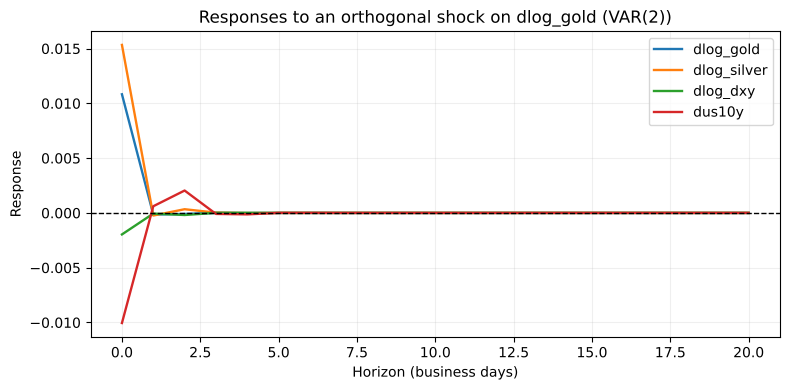

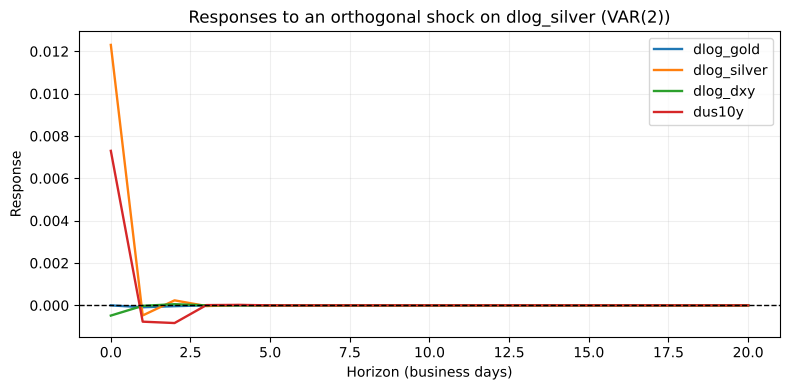

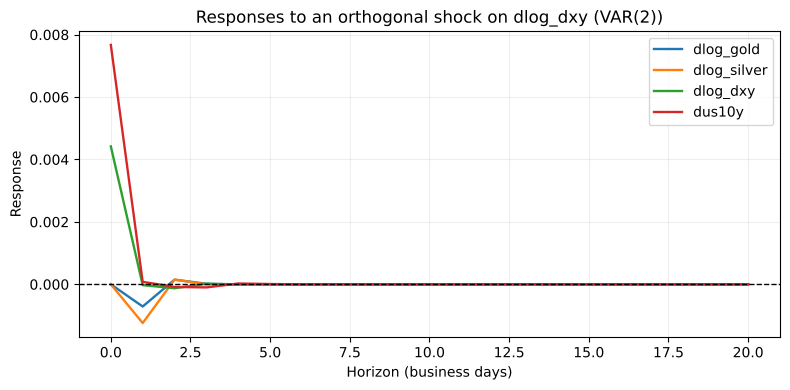

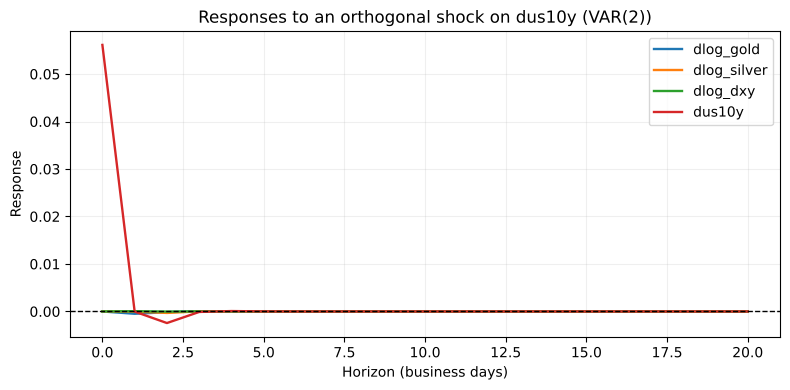

In [15]:
IRF_multi = compute_irf(final_var_multi, P_multi, H)

plot_irf(IRF_multi, ["dlog_gold", "dlog_silver", "dlog_dxy", "dus10y"], H, model_label="VAR(2)")

The four figures show the same front-loaded shape as the bivariate case: everything of any size happens within two days and the responses are nil from about h = 4.

- **Dollar shock** (+0.44% on the index). Gold and silver do not move at h = 0 by construction. At h = 1 gold falls by 0.07% and silver by 0.12%, followed by a small rebound at h = 2.
- **Rate shock** (+5.6 basis points). Gold falls by 0.05% at h = 1; silver does not react (−0.003%).

The signs match the two channels of notebook 04 and the h = 1 values reproduce its lagged coefficients. The sizes are small: a gold shock moves gold by 1.08% on the day, so the lagged dollar effect is about 7% of that and the lagged rate effect about 4.5%.

Most of the dollar-gold link is therefore not in these curves. It is contemporaneous (residual correlation −0.40), and the ordering attributes it to the gold shock. The lagged effect is statistically robust (§2.1) but economically minor next to the same-day co-movement.

## 6. Generalized impulse response (bivariate VECM, 2015-2016 episode)

For the two VECMs the Cholesky IRF is replaced by the generalized IRF of Pesaran and Shin (1998). It uses the full residual covariance matrix instead of an orthogonalized one, so the result does not depend on how the variables are ordered.

Two consequences for reading the plots:

- the shocks are no longer orthogonal, so a "gold shock" already contains the part of the silver innovation that is correlated with it. The response of gold to a silver shock is therefore not zero at h = 0, unlike in a Cholesky IRF with gold first;
- for the same reason the variance shares would not sum to 100%, so no FEVD is computed for the VECMs.

The series are in log-levels and cointegrated, so responses do not return to zero: they settle on a permanent level. The horizon is extended to 100 days to let the adjustment complete.

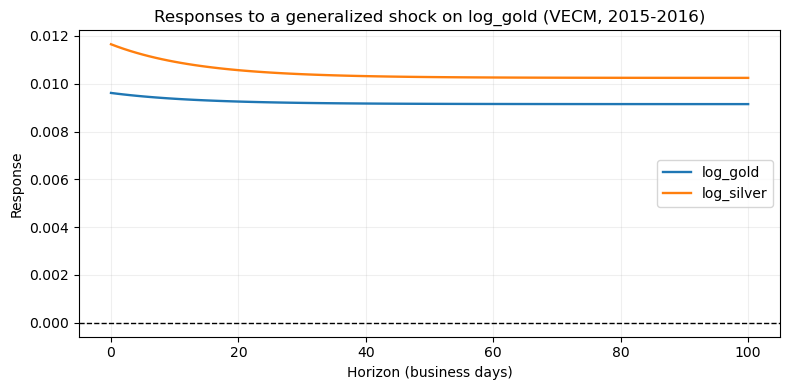

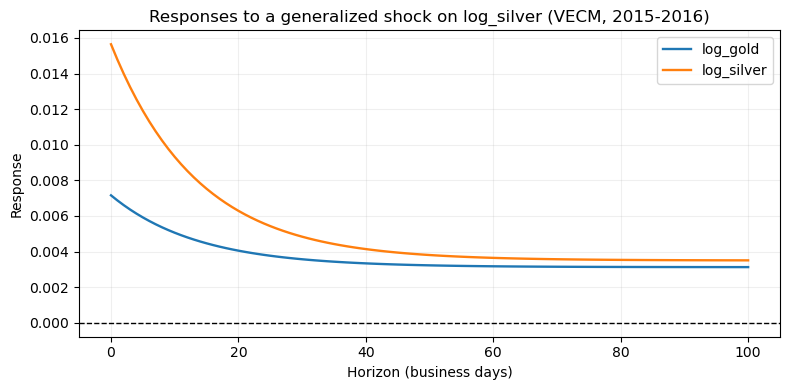

In [16]:
GIRF_bi = compute_girf(vecm_res_bi, H_VECM)

plot_irf(GIRF_bi, log_cols_bi, H_VECM, model_label="VECM, 2015-2016", shock_type="generalized")

- **Gold shock.** Gold rises by 0.96% on impact and settles around 0.92%; silver rises by 1.17% and settles around 1.03%. Almost the whole move is permanent.
- **Silver shock.** Silver rises by 1.56% on impact but keeps only about 0.35% in the long run; gold goes from 0.72% to about 0.32%. Roughly three quarters of the initial move in silver is reversed.

In both cases the adjustment is complete after 50 to 60 business days, and the long-run responses of silver and gold stay in a ratio of about 1.1, which is the cointegrating relation of notebook 03 (1 / 0.893 ≈ 1.12).

The asymmetry is the result of this section: a gold shock is absorbed as a permanent change in the level of both metals, while a silver shock is mostly transitory. It says the same thing as the adjustment coefficients of notebook 03 (silver corrects the disequilibrium, gold does not), from the impulse-response side. The window has 197 observations and the curves carry no confidence bands, so the orders of magnitude matter more than the exact values.

Comparison with the original study. The gold-shock figure is identical to the one in the report: for the variable placed first, the generalized shock and the Cholesky shock coincide by construction. The silver-shock figure differs, because the report plotted the Cholesky-orthogonalized response: there, gold starts at exactly zero and both metals end up negative in the long run (around −0.55% for gold and −0.6% for silver), which has no economic reading. The generalized shock includes the same-day co-movement (0.72% for gold on impact) and both long-run responses stay positive.

## 7. Generalized impulse response (multivariate VECM, 2013-2017 episode)

Same method, applied to the local multivariate VECM estimated on 2013-01-22 → 2017-09-05, the model analysed in notebook 04. The original study computed this GIRF on the full-sample re-estimation instead; the local window is used here so that the impulse responses and the β and α coefficients discussed in notebook 04 come from the same model.

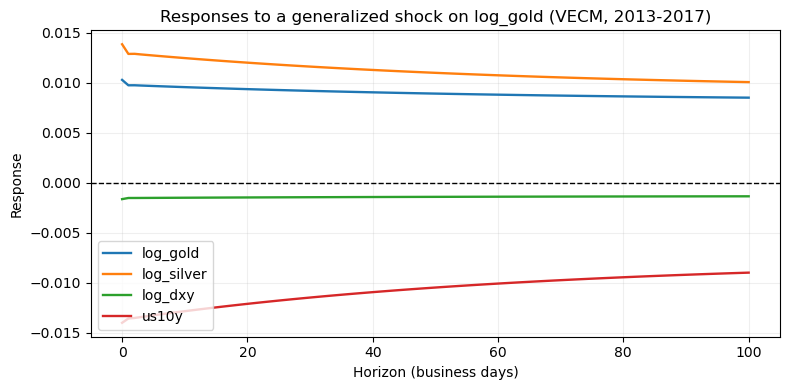

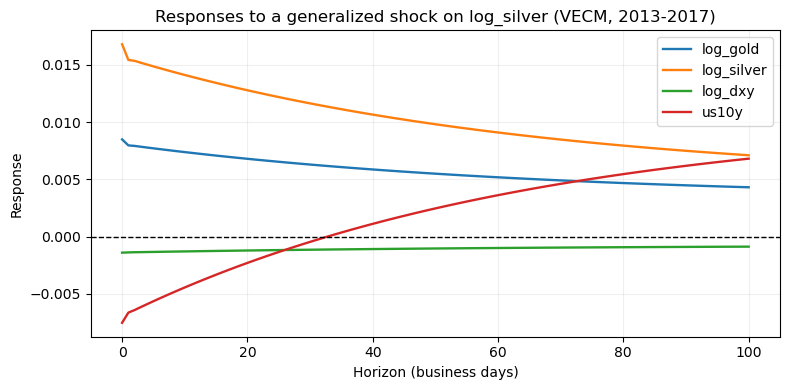

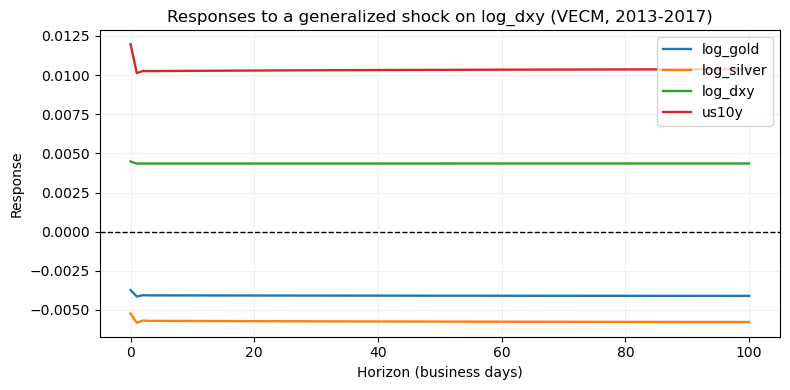

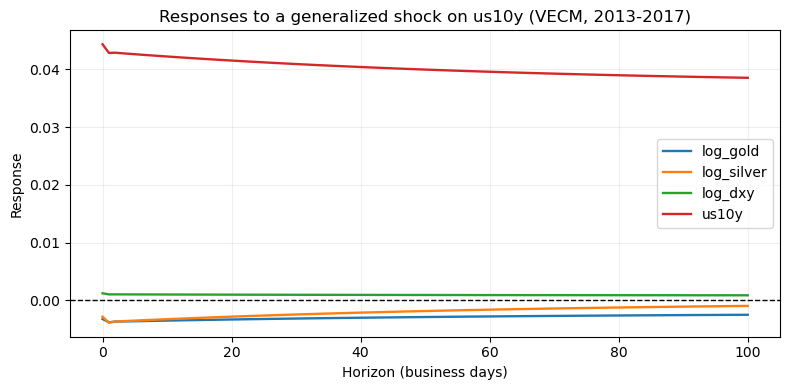

In [17]:
GIRF_multi = compute_girf(vecm_res_multi, H_VECM)

plot_irf(GIRF_multi, log_cols_multi, H_VECM, model_label="VECM, 2013-2017", shock_type="generalized")

The yield is in percentage points, so a response of 0.01 is one basis point.

- **Silver shock → gold: positive and persistent.** Gold rises by 0.85% on impact and is still at about 0.43% after 100 days.
- **Dollar shock → gold: negative.** For a 0.45% rise in the index, gold falls by 0.37% on impact and stays around −0.41%. The response is flat: the dollar effect is immediate and permanent.
- **Rate shock → gold: negative but small.** For a rise of about 4.4 basis points, gold falls by about 0.3% and stays near −0.25%.
- **Silver reacts more than gold to the dollar**: −0.52% on impact and −0.58% in the long run, about 1.4 times gold's response. To the rate shock it reacts like gold on impact but the effect fades (about −0.1% at 100 days).

The asymmetry of §6 is still visible: after a gold shock, gold keeps about 0.85% of an initial 1.03%, while after a silver shock silver keeps about 0.7% of an initial 1.68%.

Two cautions. Adjustment is much slower than in the bivariate episode: several curves are still drifting at h = 100, consistent with the small adjustment coefficients of notebook 04 (0.013 for gold, 0.031 for silver). And the yield's response to a silver shock changes sign along the way (from −0.75 to +0.7 basis points), which has no obvious economic reading; with Johansen not confirming rank 1 on this window and dxy and us10y not significant in β (notebook 04 §2.2 and §2.5), the long-run levels of this model are weakly identified. The signs of the dollar and rate responses are the robust part, the long-run magnitudes are not.

## 8. Robustness of the VAR impulse responses across macro regimes

This section extends the original study. The bivariate VAR(1) is re-estimated separately on each of the six macro regimes used in notebook 02, with the same lag order and the same Cholesky ordering, to check whether the full-sample IRF of §3 is representative of every period or an average of different regimes.

Given the ordering, gold's response to a silver shock is zero at h = 0 in every regime; the comparison across regimes is informative from h = 1.

In [18]:
periods = {
    "pre_crisis_global": df.loc["2000":"2007-06"],
    "global_financial_crisis": df.loc["2007-07":"2009"],
    "post_crisis_QE": df.loc["2010":"2014"],
    "commodity_stress": df.loc["2015":"2016"],
    "late_cycle_expansion": df.loc["2017":"2019"],
    "covid_shock": df.loc["2020":"2022"],
}

irf_by_regime = var_irf_by_subperiod(periods, diff_cols_bi, p=1, H=H)

comparison_gold_to_silver = irf_subperiod_comparison(
    irf_by_regime, response_idx=0, shock_idx=1,
    response_name="dlog_gold", shock_name="dlog_silver",
)
comparison_gold_to_silver

,pre_crisis_global,global_financial_crisis,post_crisis_QE,commodity_stress,late_cycle_expansion,covid_shock
Horizon (dlog_gold to dlog_silver shock),,,,,,
0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
1,4.354993e-04,-1.499590e-03,3.115406e-04,-4.812136e-05,1.952140e-04,-5.944640e-04
2,-2.314353e-05,-3.524079e-05,-1.784729e-05,3.566886e-06,-2.150118e-05,3.718005e-05
3,4.598769e-07,2.769648e-06,5.213194e-07,-2.088760e-07,1.572698e-06,-9.819337e-07
4,1.648222e-08,1.496372e-07,-1.158178e-09,1.136781e-08,-8.560457e-08,-2.261056e-08
5,-1.689038e-09,-3.128422e-09,-7.721757e-10,-6.016602e-10,3.020055e-09,3.633256e-09
6,6.061668e-11,-4.325283e-10,4.609869e-11,3.148314e-11,1.619533e-11,-1.761394e-10
7,-2.348499e-13,-2.658826e-12,-1.398848e-12,-1.639560e-12,-1.409016e-11,2.805513e-12
8,-9.469888e-14,9.752385e-13,5.987914e-15,8.521066e-14,1.485918e-12,2.225957e-13


All six regimes have enough observations to be estimated. The response of gold at h = 1 to a silver shock is:

| Regime | Response at h = 1 |
|---|---|
| pre_crisis_global | +0.044% |
| global_financial_crisis | −0.150% |
| post_crisis_QE | +0.031% |
| commodity_stress | −0.005% |
| late_cycle_expansion | +0.020% |
| covid_shock | −0.060% |

For comparison, the full-sample value is −0.009% and silver's own shock is worth about 1.2% on impact. In every regime the response is back to zero from h = 2.

`commodity_stress`, the regime that contains the 2015-2016 cointegration window, has the smallest response of the six. The cointegration found there is a property of the price levels and leaves no trace in the day-to-day return dynamics, in line with the "contemporaneous, not sequential" reading of notebook 03.

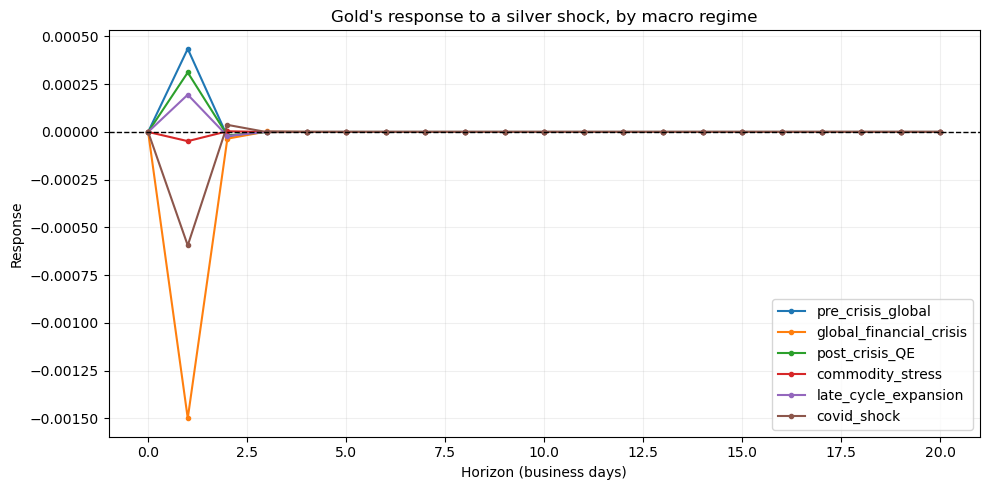

In [19]:
plt.figure(figsize=(10, 5))
for col in comparison_gold_to_silver.columns:
    plt.plot(comparison_gold_to_silver.index, comparison_gold_to_silver[col], label=col, marker="o", markersize=3)

plt.axhline(0, color="black", linewidth=1, linestyle="--")
plt.title("Gold's response to a silver shock, by macro regime")
plt.xlabel("Horizon (business days)")
plt.ylabel("Response")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

The six lines overlap everywhere except at h = 1. The global financial crisis is the outlier (−0.15%), followed by the Covid period (−0.06%); the other four regimes stay within ±0.05%.

The sign is positive in the three calm regimes and negative in the three stress regimes. The pattern is suggestive, but these are point estimates without confidence bands and the largest one is about a tenth of the impact response, so it is not evidence of a regime-dependent lagged effect. What the comparison does establish is that the full-sample IRF of §3 is representative: in no regime does a silver shock have a lasting effect on gold returns.

## 9. Conclusion

**Gold and silver (bivariate VAR, §1, §3, §4).** No Granger causality in either direction (p ≈ 0.52 and 0.37) and a very strong instantaneous link (Wald ≈ 2309, residual correlation 0.78). The impulse responses are entirely front-loaded: the full effect is on impact and less than 4% of it is left the next day. About 61% of silver's forecast error variance is common with gold. The two metals co-move within the day and neither leads the other in returns.

**Dollar and rates (multivariate VAR, §2, §5).** The dollar Granger-causes gold at every lag order from 1 to 100. Rates do so up to lag 83 and are borderline beyond. Both lagged effects have the expected negative sign but are small: on the day after a shock, gold falls by 0.07% (dollar) and 0.05% (rates), against 1.08% for its own shock. The main part of the dollar-gold link is contemporaneous (residual correlation −0.40).

**Local VECMs (§6, §7).** On the 2015-2016 episode, a gold shock is almost entirely permanent for both metals, while about three quarters of a silver shock is reversed within 50 to 60 days. This is the impulse-response counterpart of the adjustment coefficients of notebook 03 and the clearest evidence in the project for gold as the dominant side of the pair. On the 2013-2017 episode, gold responds negatively to dollar and rate shocks and silver reacts about 1.4 times more than gold to the dollar; these signs are robust, the long-run magnitudes are not.

**Regimes (§8).** The absence of lagged transmission between the two metals holds in each of the six macro regimes, including the one that contains the 2015-2016 cointegration window.

**Limits.** The Cholesky results depend on placing gold first, which is an assumption. The impulse responses are point estimates without confidence bands. The two VECM windows were selected because they show cointegration, and Johansen does not confirm rank 1 on the multivariate one, so §6-7 describe those episodes and cannot be generalized to the whole 2000-2024 period.